# Radiography Processing: Raw to Transmission

This notebook processes neutron radiography data from raw detector frames to **transmission images** (`I/I₀`), saved as `.fits`. It follows the standard reference chain used in quantitative neutron imaging (DC correction → scattered-background correction → referencing → intensity correction).

## The physics

A neutron beam attenuated by a sample follows the Beer-Lambert law:

$$I = I_0 \, e^{-\Sigma \delta}$$

where $I$ is the transmitted intensity, $I_0$ the incident intensity, $\Sigma$ [cm⁻¹] the macroscopic attenuation coefficient, and $\delta$ [cm] the sample thickness. The processed **transmission** image is the ratio $I/I_0$, obtained by dividing the corrected sample image by a corrected reference (dry or open-beam).

## The processing chain

1. **Dark current (DC):** read-out noise and camera offset, measured with no beam. Subtracted from every other image.
2. **Scattered background (SBKG):** neutrons and light scattered by the sample and setup add a bias that breaks the pure-transmission assumption. A grid of black-body (BB) dots (opaque absorbers) is imaged; the signal behind each dot is pure scattering, and interpolating those values across the field of view gives the background to subtract.
3. **Merging / exposure control:** individual frames are short. Averaging *N* frames into one increases statistics and sets the effective exposure. References (DC, OB, dry, BB) are merged fully; the experiment series is merged in user-defined batches.
4. **Referencing:** the corrected sample is divided by a corrected reference (dry cell or open beam) to yield transmission.
5. **Intensity correction:** beam intensity drifts between frames. Matching the mean value of a **non-changing area** (NCA, an unchanging high-transmission region) to the reference compensates for this drift.

Corrected, the normalization is:

$$\frac{I}{I_0} = \frac{I_\text{sample} - I_\text{DC} - I_\text{SBKG}^\text{sample}}{I_\text{ref} - I_\text{DC} - I_\text{SBKG}^\text{ref}}$$

> Run the cells top to bottom. Each stage explains what it does and shows intermediate images so you can confirm quality before moving on.

In [26]:
from pathlib import Path
import os
import numpy as np
import matplotlib.pyplot as plt
from glob import glob
from astropy.io import fits
from scipy.ndimage import median_filter

# If it errors, try '%matplotlib qt'.
%matplotlib widget

PROJECTION = "median"   # 'median' (robust to outliers) or 'mean' (matches statistics)

In [27]:
# Core I/O 
# ----------------------------------------------------------------------
def load_fits(folder):
    """Load all .fits in a folder (sorted), skipping any file with 'bad' in its name.
    Returns (list_of_arrays, list_of_paths)."""
    all_paths = glob(os.path.join(folder, "*.fits")) + \
                glob(os.path.join(folder, "*.FITS"))
    # On case-insensitive filesystems (Windows/macOS) the two globs return the
    # same files twice. Deduplicate by normalized absolute path, then sort.
    seen, paths = set(), []
    for p in all_paths:
        key = os.path.normcase(os.path.abspath(p))
        if key in seen:
            continue
        if "bad" in os.path.basename(p).lower():
            continue
        seen.add(key)
        paths.append(p)
    paths.sort()
    return [fits.getdata(p).astype(np.float32) for p in paths], paths


def project(stack, method=PROJECTION):
    """Collapse a list/array of frames along axis 0 using median or mean."""
    arr = np.stack(stack, axis=0)
    if method == "median":
        return np.median(arr, axis=0)
    if method == "mean":
        return np.mean(arr, axis=0)
    raise ValueError("method must be 'median' or 'mean'")


def remove_outliers(img, radius=1, threshold=50):
    """Replace white-spot pixels (|img - local median| > threshold) with the local median."""
    m = median_filter(img, size=2 * radius + 1, mode="reflect")
    mask = np.abs(img - m) > threshold
    out = img.copy()
    out[mask] = m[mask]
    return out


def subtract_dc(images, dc):
    """Subtract a DC frame from each image in a list."""
    return [img - dc for img in images]


def batch_average(images, group, method=PROJECTION):
    """Merge images into consecutive groups of `group`, projecting each group to one frame.
    Trailing images that don't fill a full group are discarded."""
    out = []
    for i in range(0, len(images), group):
        chunk = images[i:i + group]
        if len(chunk) == group:
            out.append(project(chunk, method=method))
    return out


def save_unique(image, base_name, folder, clip_below=None, clip_above=None):
    """Save `image` as base_name_NN.fits, auto-incrementing NN to avoid overwrite."""
    if clip_below is not None:
        image = np.maximum(image, clip_below)
    if clip_above is not None:
        image = np.minimum(image, clip_above)
    Path(folder).mkdir(parents=True, exist_ok=True)
    for i in range(100):
        name = f"{base_name}_{i:02d}.fits"
        path = os.path.join(folder, name)
        if not os.path.exists(path):
            fits.writeto(path, image.astype(np.float32), overwrite=False)
            return path
    raise RuntimeError("Could not find a free filename (00-99 all exist).")

# Stage 1 — Select the data folders

Pick the **parent** folder (e.g. `exp 200`). The notebook scans its subfolders and auto-detects the five roles by name (case-insensitive substring match):

| Role | Matches subfolder containing | Required? |
|------|------------------------------|-----------|
| **DC**  | `dc`            | **Yes** |
| **OB**  | `ob`            | one of these |
| **BB**  | `bb`            | optional (enables SBKG) |
| **dry** | `dry`           | one of these |
| **Exp** | `meas` or `exp` | the sample series |

**DC is always required**, plus at least one of OB / dry / Exp. After auto-detection you can confirm or override each folder individually (a Tkinter dialog opens for any you choose to change). Image filenames are preserved and may carry chemistry/condition info; nothing in the names is altered.

In [28]:
import tkinter as tk
from tkinter import filedialog

def _tk_root():
    r = tk.Tk()
    r.withdraw()
    r.attributes("-topmost", True)
    return r

def pick_folder(title):
    r = _tk_root()
    path = filedialog.askdirectory(title=title)
    r.destroy()
    return Path(path) if path else None

# Token -> role. 'meas'/'exp' both map to the experiment slot.
ROLE_TOKENS = {
    "dc":  "dc",
    "ob":  "ob",
    "bb":  "bb",
    "dry": "dry",
    "meas": "exp",
    "exp":  "exp",
}
REFS_TOKENS = ("refs", "ref")   # folder that nests dc/ob/bb

def _scan(dirs, found):
    """Match each dir in `dirs` to a role by substring; first match per role wins."""
    for sub in sorted(dirs):
        name = sub.name.lower()
        # don't let the refs container itself match a role
        if name in REFS_TOKENS:
            continue
        for token, role in ROLE_TOKENS.items():
            if token in name and role not in found:
                found[role] = sub
                break

def auto_detect(parent):
    """Scan parent's subfolders, plus inside any refs/ref subfolder.
    Returns {role: Path}."""
    found = {}
    top = [p for p in parent.iterdir() if p.is_dir()]
    # first scan inside refs/ (where dc/ob/bb usually live)
    for r in top:
        if r.name.lower() in REFS_TOKENS:
            _scan([p for p in r.iterdir() if p.is_dir()], found)
    # then scan the parent's own subfolders (dry, meas/exp, and any refs not nested)
    _scan(top, found)
    return found

# --- pick the parent and auto-detect ---
parent = pick_folder("Select the PARENT folder (e.g. 'exp 200')")
if parent is None:
    raise RuntimeError("No parent folder selected.")

folders = auto_detect(parent)

print(f"Parent: {parent}\n")
print("Auto-detected:")
for role in ["dc", "ob", "bb", "dry", "exp"]:
    f = folders.get(role)
    n = len(load_fits(f)[1]) if f else 0
    # show the path relative to parent so the refs/ nesting is visible
    rel = f.relative_to(parent) if f else None
    status = f"{rel}  ({n} .fits)" if f else "-- not found --"
    print(f"  {role:4s}: {status}")

output_folder = parent / "results"
output_folder.mkdir(exist_ok=True)
print(f"\nOutput -> {output_folder}")
#print("\nIf any role is wrong or missing, run the OVERRIDE cell below to fix it.")

Parent: C:\Users\carreon_r\Documents\90_Python\Binder-collab\2507_BT_ICON_Elec\03_meas\exp3xx\exp300

Auto-detected:
  dc  : refs\dc  (10 .fits)
  ob  : refs\ob  (10 .fits)
  bb  : refs\bb  (10 .fits)
  dry : dry  (20 .fits)
  exp : meas  (60 .fits)

Output -> C:\Users\carreon_r\Documents\90_Python\Binder-collab\2507_BT_ICON_Elec\03_meas\exp3xx\exp300\results


# Stage 2 — DC correction and reference merging

The dark-current stack is merged (median/mean per `PROJECTION`) into a single DC frame. That DC frame is subtracted from every image in the OB, dry, and BB folders. Each of those is then merged to a single clean reference frame.

- **DC merge:** one frame from the DC stack.
- **OB / dry / BB:** each loaded, DC-subtracted frame by frame, optionally white-spot cleaned, then merged.

White-spot removal (`REMOVE_SPOTS`) replaces gamma-spot outliers with a local median. Leave it on for clean references; turn it off to inspect the raw DC-corrected merge.

The merged references produced here feed the later stages: BB → SBKG estimation (Stage 3), dry/OB → referencing (Stage 5–6).

In [29]:
REMOVE_SPOTS = True   # apply white-spot removal to OB/dry/BB references 

def merge_reference(folder, dc, remove_spots=REMOVE_SPOTS, method=PROJECTION):
    """Load a reference folder, subtract DC from each frame, optional spot removal,
    then merge to one frame. Returns (merged_frame, n_loaded)."""
    imgs, paths = load_fits(str(folder))
    if not imgs:
        return None, 0
    corr = subtract_dc(imgs, dc)
    if remove_spots:
        corr = [remove_outliers(im) for im in corr]
    return project(corr, method=method), len(imgs)

# --- merge DC (no spot removal: DC is left exactly as measured) ---
dc_imgs, _ = load_fits(str(folders["dc"]))
assert dc_imgs, "DC folder has no .fits files."
dc_frame = project(dc_imgs, method=PROJECTION)
print(f"DC merged from {len(dc_imgs)} frames, shape {dc_frame.shape}")

# --- merge each available reference, DC-corrected + spot-cleaned ---
refs = {}
for role in ("ob", "dry", "bb"):
    if role in folders:
        frame, n = merge_reference(folders[role], dc_frame)
        refs[role] = frame
        print(f"{role.upper():3s} merged from {n} DC-corrected frames")
    else:
        print(f"{role.upper():3s} -- skipped (folder not provided)")

DC merged from 10 frames, shape (2048, 2048)
OB  merged from 10 DC-corrected frames
DRY merged from 20 DC-corrected frames
BB  merged from 10 DC-corrected frames


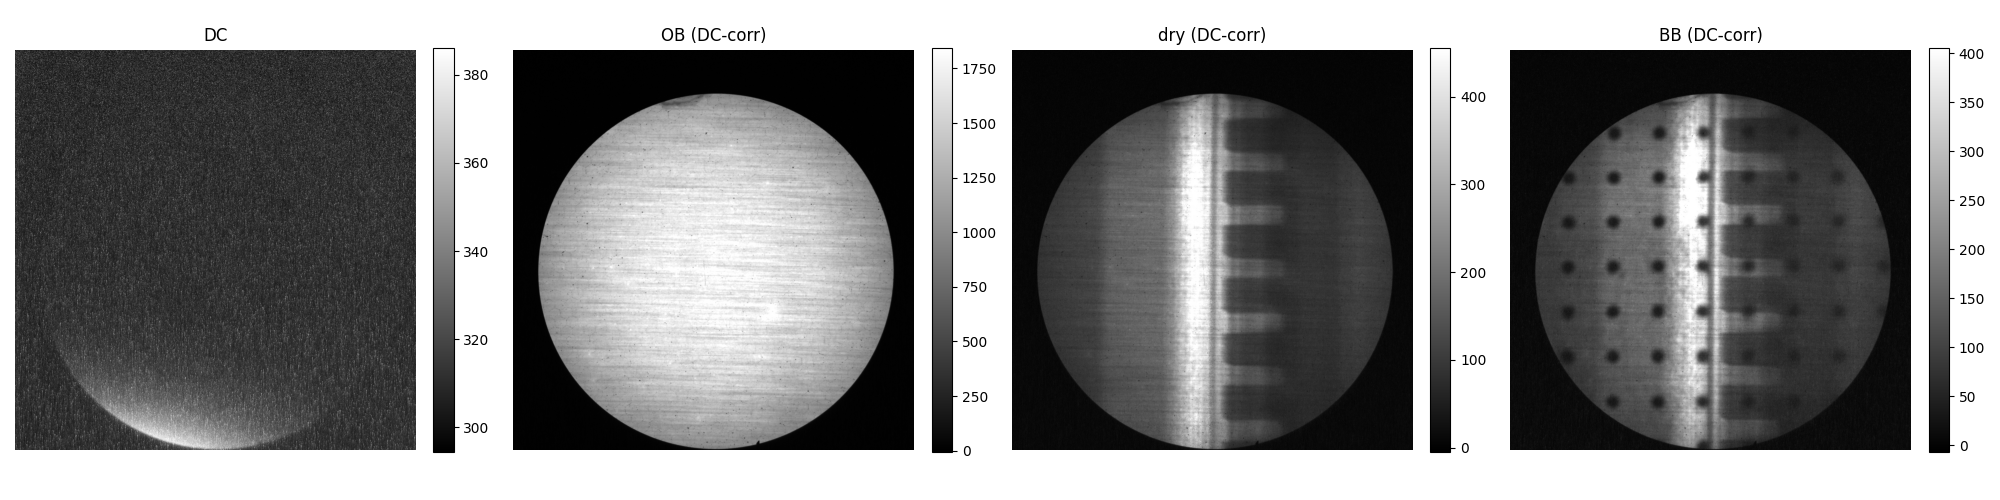

In [30]:
def show_frames(named_frames, vmin=None, vmax=None, size=5):
    """Display a row of (title, frame) pairs side by side."""
    items = [(t, f) for t, f in named_frames if f is not None]
    if not items:
        print("Nothing to display.")
        return
    fig, axes = plt.subplots(1, len(items), figsize=(size * len(items), size))
    if len(items) == 1:
        axes = [axes]
    for ax, (title, frame) in zip(axes, items):
        lo = np.percentile(frame, 1) if vmin is None else vmin
        hi = np.percentile(frame, 99) if vmax is None else vmax
        im = ax.imshow(frame, cmap="gray", origin="lower", vmin=lo, vmax=hi)
        ax.set_title(title)
        ax.axis("off")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()

show_frames([
    ("DC", dc_frame),
    ("OB (DC-corr)", refs.get("ob")),
    ("dry (DC-corr)", refs.get("dry")),
    ("BB (DC-corr)", refs.get("bb")),
])

# Stage 3 — Scattered background (SBKG) correction

The DC-corrected **BB image** has dark dots where the black-body absorbers block all transmitted neutrons. The signal remaining behind each dot is pure **scattered background**: neutrons and light reaching the detector by scattering rather than direct transmission.

The estimation has three steps:

1. **Detect the dots.** Two methods are available (set `MASK_METHOD`):
   - `"otsu"`: normalize BB by OB, Otsu-threshold to separate dark dots, clean small objects, label, and take each dot's centre of mass (Carminati's approach).
   - `"minima"`: find local intensity minima directly (dots are the darkest spots).
2. **Sample behind the dots.** A small disc at each dot centre gives the local scattered-background value.
3. **Interpolate across the FOV.** A 2nd-order polynomial `a + bx + cx² + dxy + ey + fy²` is least-squares fit to the dot-centre values, producing a smooth SBKG surface for every pixel.

This SBKG image is subtracted (alongside DC) from the sample and reference images in later stages. SBKG requires a BB folder; if none was provided, this stage is skipped and `sbkg` stays `None`.

In [47]:
# ============================================================
from scipy.ndimage import (gaussian_filter, median_filter, label, binary_opening, binary_erosion, zoom, distance_transform_edt)

# ---------------- parameters ----------------
# All tunables in one place. Values measured from the real BB frame.

# Beam area
BEAM_PERCENTILE = 22      # OB pixels above this percentile = inside the beam
BEAM_ERODE      = 20      # pull the beam mask in from the rim (px)

# Local background (for finding dark dots)
BG_MEDIAN_SIZE  = 151     # median window in full-res px (> dot, < spacing)
BG_DOWNSCALE    = 3       # compute background at 1/N size for speed

# Dot detection (clean dots only, used to seed the lattice)
DOT_DROP        = 0.9    # a dot pixel sits below this fraction of local background
DOT_RADIUS      = 22      # sampling disc radius at each dot (~ dot radius)
MIN_DOT_AREA    = 300     # reject blobs smaller than this (noise)
MAX_DOT_AREA    = 8000    # reject blobs larger than this (merged sample bands)
ROUND_ASPECT    = 2.0     # keep roughly round blobs: 1/ASPECT < w/h < ASPECT
ROUND_FILL      = 0.5     # keep blobs filling > this fraction of their bounding box

# Lattice fit + constrained snap
ROW_TOL         = 80      # tolerance for clustering dots into grid rows/cols (px)
SNAP_SMALL      = 25      # constrained snap half-window (small, on purpose)
SNAP_DIP        = 0.95    # accept a snap only if ratio there < this; else keep grid pos
EDGE_MARGIN     = 35      # reject lattice nodes within this many px of the beam edge

# Polynomial fit
SIGMA_CLIP      = 2.98     # drop dots deviating > this many sigma from the fitted surface
SIGMA_ITERS     = 5       # max refit iterations

  lattice pitch: drow=229 dcol=231  (47 nodes)
clean=50  nodes=47  snapped=43
dots used in fit: 43
SBKG over beam: 3.1% to 5.1% of OB


C:\Users\carreon_r\AppData\Local\Temp\ipykernel_35160\1419576916.py:202: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=(8, 8))


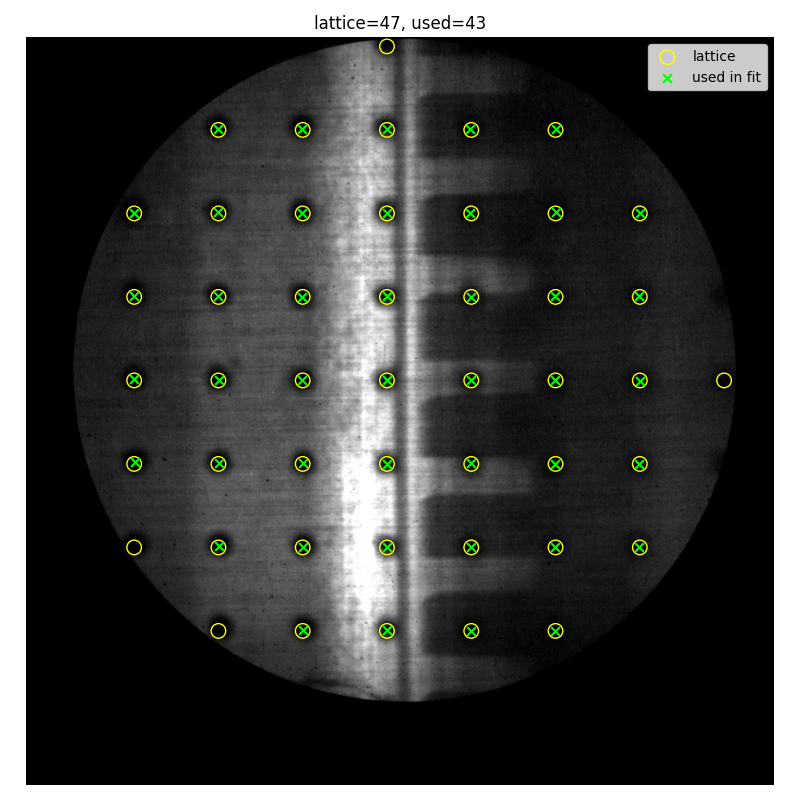

In [48]:
# BB scattered-background (SBKG) estimation
#
# Detects the black-body dot grid, fits a regular lattice, samples the
# scattered-background value behind each dot, and fits a smooth 2nd-order
# polynomial surface (the SBKG image) to subtract downstream.
# ============================================================
from scipy.ndimage import (gaussian_filter, median_filter, label,
                           binary_opening, binary_erosion, zoom,
                           distance_transform_edt)



# ---------------- beam + background ----------------
def beam_mask(ref):
    """Boolean mask of the illuminated beam area, pulled in from the rim."""
    m = ref > np.percentile(ref, BEAM_PERCENTILE)
    m = binary_opening(m, iterations=2)
    m = binary_erosion(m, iterations=BEAM_ERODE)
    return m

def local_background(bb):
    """Smooth local background via a median filter computed on a downscaled image
    (fast, and the background is smooth so downscaling costs no accuracy)."""
    small = zoom(bb, 1 / BG_DOWNSCALE, order=1)
    win = max(3, int(round(BG_MEDIAN_SIZE / BG_DOWNSCALE)) | 1)
    med = median_filter(small, size=win)
    med = zoom(med, np.array(bb.shape) / np.array(small.shape), order=1)
    med = med[:bb.shape[0], :bb.shape[1]]
    if med.shape != bb.shape:
        med = np.pad(med, [(0, bb.shape[0] - med.shape[0]),
                           (0, bb.shape[1] - med.shape[1])], mode="edge")
    return med

# ---------------- dot detection ----------------
def detect_round_dots(ratio, mask):
    """Find clean, round dark dots (BB/background ratio dips). These seed the lattice;
    merged sample-band blobs are rejected by the area and roundness filters."""
    d = (ratio < DOT_DROP) & mask & np.isfinite(ratio)
    d = binary_opening(d, iterations=2)
    lbl, n = label(d)
    centres = []
    for i in range(1, n + 1):
        ys, xs = np.where(lbl == i)
        area = ys.size
        if not (MIN_DOT_AREA <= area <= MAX_DOT_AREA):
            continue
        h = ys.max() - ys.min() + 1
        w = xs.max() - xs.min() + 1
        round_enough = (1 / ROUND_ASPECT) < w / h < ROUND_ASPECT
        filled_enough = area / (h * w) > ROUND_FILL
        if round_enough and filled_enough:
            centres.append((ys.mean(), xs.mean()))
    return np.array(centres)

# ---------------- lattice ----------------
def _cluster_1d(values, tol):
    """Group sorted 1-D coordinates into clusters separated by gaps > tol.
    Returns the mean of each cluster (i.e. the grid line positions)."""
    v = np.sort(values)
    groups = [[v[0]]]
    for x in v[1:]:
        if x - groups[-1][-1] < tol:
            groups[-1].append(x)
        else:
            groups.append([x])
    return np.array([np.mean(g) for g in groups])

def fit_lattice(clean, shape, mask):
    """Fit a regular lattice to the clean dots and return all in-beam nodes.

    Pitch is measured from the histogram of pairwise distances (robust to dots on
    the sample bands that don't sit on the true grid), and the origin from the
    circular phase that best aligns all dots. This avoids the row/column
    clustering that contaminated dots were corrupting.
    """
    def robust_pitch(coords):
        coords = np.sort(coords)
        diffs = []
        for i in range(len(coords)):
            for j in range(i + 1, len(coords)):
                dd = coords[j] - coords[i]
                if 100 < dd < 400:           # plausible single-step spacing range
                    diffs.append(dd)
        diffs = np.array(diffs)
        hist, edges = np.histogram(diffs, bins=np.arange(100, 400, 10))
        peak = edges[np.argmax(hist)] + 5    # dominant spacing
        near = diffs[np.abs(diffs - peak) < 30]
        return np.median(near)

    def best_phase(coords, step):
        ang = 2 * np.pi * (coords % step) / step
        m = np.arctan2(np.sin(ang).mean(), np.cos(ang).mean())
        return (m / (2 * np.pi)) * step % step

    drow = robust_pitch(clean[:, 0])
    dcol = robust_pitch(clean[:, 1])
    r0 = best_phase(clean[:, 0], drow)
    c0 = best_phase(clean[:, 1], dcol)

    H, W = shape
    nodes = []
    r = r0
    while r < H:
        c = c0
        while c < W:
            if 0 <= int(r) < H and 0 <= int(c) < W and mask[int(r), int(c)]:
                nodes.append((r, c))
            c += dcol
        r += drow
    print(f"  lattice pitch: drow={drow:.0f} dcol={dcol:.0f}  ({len(nodes)} nodes)")
    return nodes

def constrained_snap(bb, ratio, nodes, mask):
    """Snap each lattice node to the intensity-weighted centroid of the dark dip
    in a small window. If there is no real dip (sample band, bright stripe),
    keep the grid position. Centroid is more accurate than the darkest pixel."""
    H, W = bb.shape
    edist = distance_transform_edt(mask)
    out = []
    for (r, c) in nodes:
        ri, ci = int(r), int(c)
        if edist[ri, ci] < EDGE_MARGIN:
            continue
        r0, r1 = max(0, ri - SNAP_SMALL), min(H, ri + SNAP_SMALL + 1)
        c0, c1 = max(0, ci - SNAP_SMALL), min(W, ci + SNAP_SMALL + 1)
        patch = ratio[r0:r1, c0:c1]
        dip = patch < SNAP_DIP
        if dip.sum() < 20:                      # no real dot -> keep grid position
            out.append((r, c))
            continue
        wy, wx = np.where(dip)
        weights = SNAP_DIP - patch[dip]         # darker pixels weigh more
        cy = r0 + np.average(wy, weights=weights)
        cx = c0 + np.average(wx, weights=weights)
        out.append((cy, cx))
    return out

# ---------------- polynomial surface ----------------
def sample_dot_values(img, centres, radius=DOT_RADIUS):
    """Median intensity in a disc around each dot centre."""
    H, W = img.shape
    xs, ys, vals = [], [], []
    for (cy, cx) in centres:
        cy, cx = int(round(cy)), int(round(cx))
        patch = img[max(0, cy - radius):min(H, cy + radius + 1),
                    max(0, cx - radius):min(W, cx + radius + 1)]
        if patch.size:
            xs.append(cx); ys.append(cy); vals.append(np.median(patch))
    return np.array(xs), np.array(ys), np.array(vals)

def fit_poly2(xs, ys, vals, shape):
    """Least-squares 2nd-order 2D polynomial, evaluated over the full grid."""
    A = np.column_stack([np.ones_like(xs), xs, xs**2, xs*ys, ys, ys**2]).astype(float)
    coeffs, *_ = np.linalg.lstsq(A, vals.astype(float), rcond=None)
    H, W = shape
    yy, xx = np.mgrid[0:H, 0:W]
    xf, yf = xx.ravel(), yy.ravel()
    G = np.column_stack([np.ones_like(xf), xf, xf**2, xf*yf, yf, yf**2])
    return (G @ coeffs).reshape(shape), coeffs

def fit_with_sigma_clip(bb, centres, shape):
    """Fit the polynomial, iteratively dropping outlier dots (e.g. on the sample
    block) and refitting, so a few bad points cannot distort the surface."""
    centres = list(centres)
    for _ in range(SIGMA_ITERS):
        xs, ys, vals = sample_dot_values(bb, centres)
        if len(vals) < 6:
            raise RuntimeError(f"Only {len(vals)} dots left after clipping.")
        surface, coeffs = fit_poly2(xs, ys, vals, shape)
        resid = vals - surface[ys.astype(int), xs.astype(int)]
        s = np.std(resid)
        if s == 0:
            break
        keep = np.abs(resid) < SIGMA_CLIP * s
        if keep.all():
            break
        centres = [centres[i] for i in range(len(centres)) if keep[i]]
    return surface, centres, coeffs

# ---------------- run ----------------
sbkg = bb_centres = bb_mask = None
if "bb" in refs and refs["bb"] is not None:
    bb_frame = refs["bb"]
    beam_ref = refs.get("ob") if refs.get("ob") is not None else bb_frame

    bb_mask = beam_mask(beam_ref)
    ratio = gaussian_filter(bb_frame, 2) / local_background(bb_frame)

    clean   = detect_round_dots(ratio, bb_mask)
    nodes   = fit_lattice(clean, bb_frame.shape, bb_mask)
    snapped = constrained_snap(bb_frame, ratio, nodes, bb_mask)
    print(f"clean={len(clean)}  nodes={len(nodes)}  snapped={len(snapped)}")

    sbkg, bb_centres, coeffs = fit_with_sigma_clip(bb_frame, snapped, bb_frame.shape)
    print(f"dots used in fit: {len(bb_centres)}")
    if refs.get("ob") is not None:
        frac = 100 * sbkg / np.maximum(refs["ob"], 1e-6)
        print(f"SBKG over beam: {np.percentile(frac[bb_mask], 5):.1f}% to "
              f"{np.percentile(frac[bb_mask], 95):.1f}% of OB")

    # overlay: lattice (yellow) vs dots used in the fit (green)
    fig, ax = plt.subplots(figsize=(8, 8))
    lo, hi = np.percentile(bb_frame[bb_mask], [1, 99])
    ax.imshow(bb_frame, cmap="gray", origin="upper", vmin=lo, vmax=hi)
    ax.scatter([c[1] for c in nodes], [c[0] for c in nodes],
               s=110, edgecolor="yellow", facecolor="none", label="lattice")
    ax.scatter([c[1] for c in bb_centres], [c[0] for c in bb_centres],
               s=40, c="lime", marker="x", label="used in fit")
    ax.legend(loc="upper right")
    ax.set_title(f"lattice={len(nodes)}, used={len(bb_centres)}")
    ax.axis("off"); plt.tight_layout(); plt.show()
else:
    print("No BB -> SBKG skipped.")

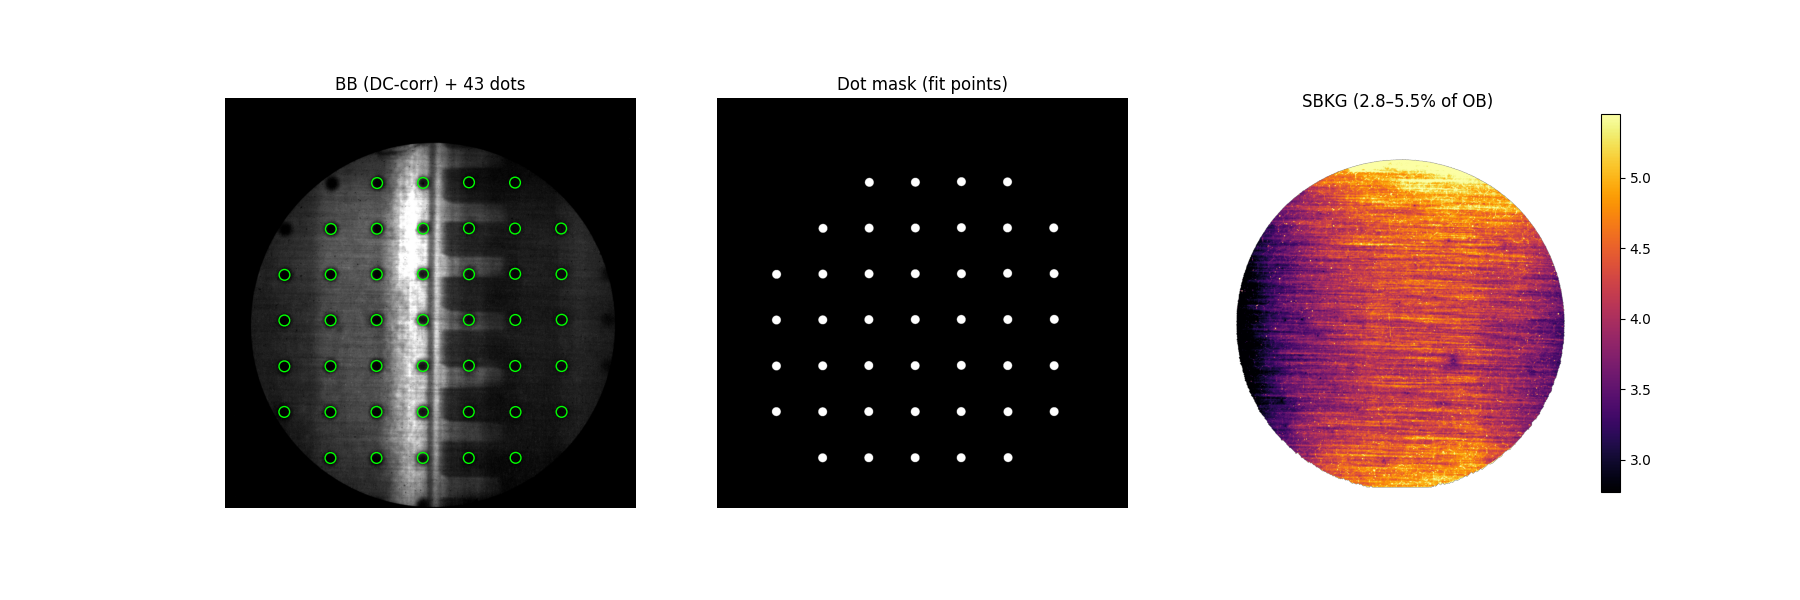

In [49]:
# BB | dot mask | SBKG surface
# ============================================================
if sbkg is not None:
    # build a dot mask: filled discs at each dot centre used in the fit
    dot_mask = np.zeros(bb_frame.shape, dtype=bool)
    yy, xx = np.ogrid[:bb_frame.shape[0], :bb_frame.shape[1]]
    for (cy, cx) in bb_centres:
        dot_mask |= (yy - cy)**2 + (xx - cx)**2 <= DOT_RADIUS**2

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    # 1) BB with dot centres
    lo, hi = np.percentile(bb_frame[bb_mask], [1, 99])
    axes[0].imshow(bb_frame, cmap="gray", origin="lower", vmin=lo, vmax=hi)
    axes[0].scatter([c[1] for c in bb_centres], [c[0] for c in bb_centres],
                    s=60, edgecolor="lime", facecolor="none")
    axes[0].set_title(f"BB (DC-corr) + {len(bb_centres)} dots")
    axes[0].axis("off")

    # 2) dot mask
    axes[1].imshow(dot_mask, cmap="gray", origin="lower")
    axes[1].set_title("Dot mask (fit points)")
    axes[1].axis("off")

    # 3) SBKG surface as % of OB
    if refs.get("ob") is not None:
        disp = 100 * sbkg / np.maximum(refs["ob"], 1e-6)
        disp = np.where(bb_mask, disp, np.nan)
        # scale to the in-beam percentile range so faint structure shows
        vlo, vhi = np.nanpercentile(disp, [2, 98])
        im = axes[2].imshow(disp, cmap="inferno", origin="lower", vmin=vlo, vmax=vhi)
        axes[2].set_title(f"SBKG ({vlo:.1f}–{vhi:.1f}% of OB)")
    else:
        disp = np.where(bb_mask, sbkg, np.nan)
        vlo, vhi = np.nanpercentile(disp, [2, 98])
        im = axes[2].imshow(disp, cmap="inferno", origin="lower", vmin=vlo, vmax=vhi)
        axes[2].set_title("SBKG (counts)")
    axes[2].axis("off")
    fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)



### STAGE 4 — Experiment series: batch-average + DC + SBKG correction

 Loads the experiment frames, groups them into batches of BATCH_SIZE (exposure control), and for each batch: 
 
 DC-subtract -> optional spot
 removal -> merge -> subtract the SBKG surface. Each corrected batch is
 saved as its own FITS in tomo/ (radiography output folder).


In [51]:
from tqdm.notebook import tqdm

# ============================================================
# STAGE 4 — Experiment series: batch-average + DC + SBKG correction
#
# Loads the experiment frames, groups them into batches of BATCH_SIZE
# (exposure control), and for each batch: DC-subtract -> optional spot
# removal -> merge -> subtract the SBKG surface. Each corrected batch is
# saved as its own FITS.
# ============================================================
BATCH_SIZE = 10      # frames merged per output image

if "exp" not in folders:
    raise RuntimeError("No experiment folder selected (Stage 1).")

exp_imgs, exp_paths = load_fits(str(folders["exp"]))
n = len(exp_imgs)
n_batches = n // BATCH_SIZE
usable = n_batches * BATCH_SIZE
if usable != n:
    print(f"Warning: {n - usable} trailing frame(s) won't fill a batch and are discarded.")
print(f"{n} frames -> {n_batches} batches of {BATCH_SIZE}")

# SBKG to subtract (same surface for every batch); zero if no BB was processed
sbkg_exp = sbkg if sbkg is not None else 0.0
if sbkg is None:
    print("No SBKG available -> only DC correction applied.")

# output folder for corrected radiographs
exp_out = output_folder / "exp_corrected"
exp_out.mkdir(parents=True, exist_ok=True)

exp_batches = []   # keep corrected batches in memory for Stage 6 referencing
stem = folders["exp"].name

for b in tqdm(range(n_batches), desc="Batches"):
    group = exp_imgs[b * BATCH_SIZE : (b + 1) * BATCH_SIZE]
    corr = subtract_dc(group, dc_frame)
    if REMOVE_SPOTS:
        corr = [remove_outliers(im) for im in corr]
    merged = project(corr, method=PROJECTION)
    merged = merged - sbkg_exp
    exp_batches.append(merged)
    out = exp_out / f"exp_{stem}_batch_{b:04d}.fits"
    fits.writeto(out, merged.astype(np.float32), overwrite=True)

print(f"Saved {len(exp_batches)} corrected batches in {exp_out}")

60 frames -> 6 batches of 10


Batches:   0%|          | 0/6 [00:00<?, ?it/s]

Saved 6 corrected batches in C:\Users\carreon_r\Documents\90_Python\Binder-collab\2507_BT_ICON_Elec\03_meas\exp3xx\exp300\results\exp_corrected


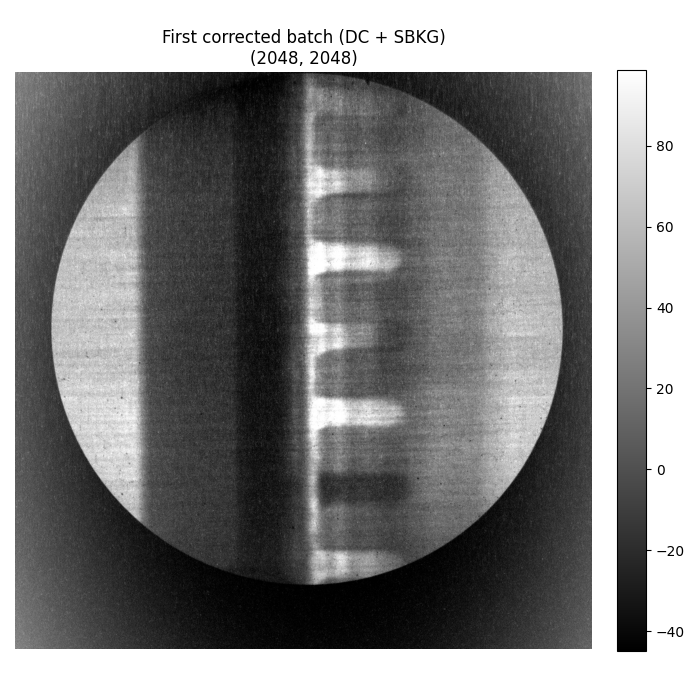

In [52]:
# Quick look at the first corrected batch
fig, ax = plt.subplots(figsize=(7, 7))
data = exp_batches[0]
m = bb_mask if bb_mask is not None else np.ones_like(data, bool)
lo, hi = np.percentile(data[m], [1, 99])
im = ax.imshow(data, cmap="gray", origin="upper", vmin=lo, vmax=hi)
ax.set_title(f"First corrected batch (DC + SBKG)\n{exp_batches[0].shape}")
ax.axis("off"); fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout(); plt.show()

Reference 'dry' corrected (DC + SBKG), shape (2048, 2048)


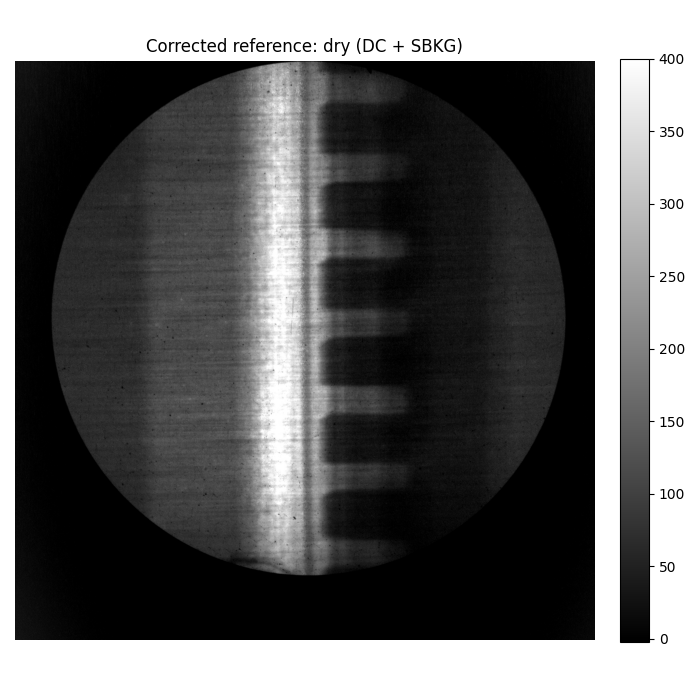

In [53]:
# ============================================================
# STAGE 5 — Correct the reference (dry or OB): DC + SBKG
#
# The reference is corrected the same way as the experiment so the
# division in Stage 6 is consistent. You choose which reference to use
# for transmission: dry (sample cell, no active material) or OB (open beam).
# ============================================================
REFERENCE = "dry"     # "dry" or "ob" — which reference to normalize against

if REFERENCE not in refs or refs[REFERENCE] is None:
    raise RuntimeError(f"Reference '{REFERENCE}' not available. "
                       f"Have: {[k for k,v in refs.items() if v is not None]}")

# refs[REFERENCE] is already DC-corrected and spot-cleaned (Stage 2).
# Subtract the SBKG surface so it matches the experiment correction.
ref_corrected = refs[REFERENCE] - (sbkg if sbkg is not None else 0.0)
print(f"Reference '{REFERENCE}' corrected (DC + SBKG), shape {ref_corrected.shape}")

# quick look
fig, ax = plt.subplots(figsize=(7, 7))
m = bb_mask if bb_mask is not None else np.ones_like(ref_corrected, bool)
lo, hi = np.percentile(ref_corrected[m], [1, 99])
im = ax.imshow(ref_corrected, cmap="gray", origin="upper", vmin=lo, vmax=hi)
ax.set_title(f"Corrected reference: {REFERENCE} (DC + SBKG)")
ax.axis("off"); fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout(); plt.show()

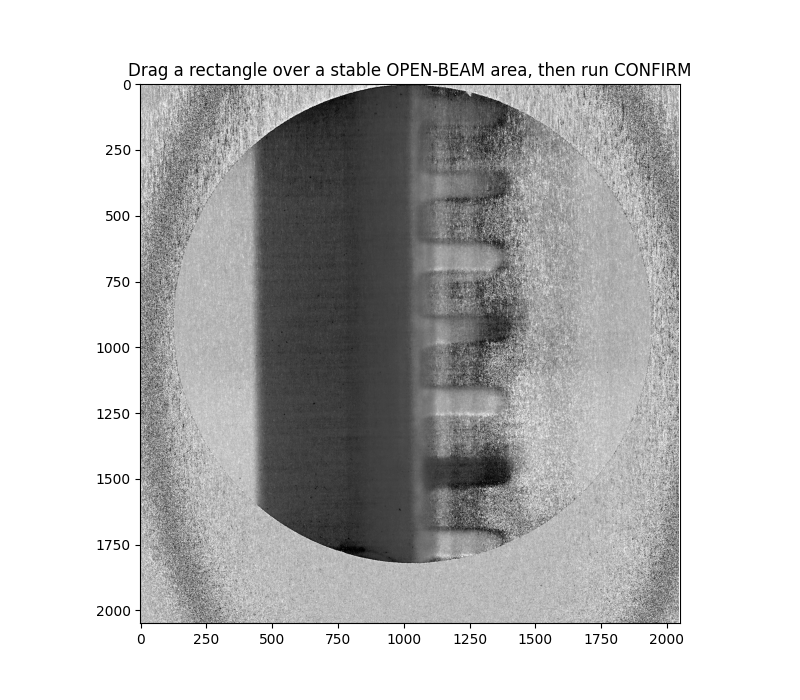

In [55]:
# ============================================================
# STAGE 6a — Select the non-changing area (NCA)
#
# Draw a rectangle over a region that is ALWAYS open beam in the
# experiment (no sample, no bubbles, stable). Its mean transmission
# should be 1; we use it to correct beam-intensity drift per batch.
# Run this cell, drag a rectangle, then run the CONFIRM cell.
# ============================================================
from matplotlib.widgets import RectangleSelector

nca_roi = None
_nca_selector = None
_nca_pending = None

# show transmission of the first batch as the canvas to draw on
_first_trans = exp_batches[0] / np.where(np.abs(ref_corrected) > 1e-6,
                                         ref_corrected, np.nan)

fig, ax = plt.subplots(figsize=(8, 7))
m = bb_mask if bb_mask is not None else np.ones_like(_first_trans, bool)
vlo, vhi = np.nanpercentile(np.where(m, _first_trans, np.nan), [2, 98])
ax.imshow(_first_trans, cmap="gray", origin="upper", vmin=vlo, vmax=vhi)
ax.set_title("Drag a rectangle over a stable OPEN-BEAM area, then run CONFIRM")

def _on_nca(eclick, erelease):
    global _nca_pending
    c0, c1 = sorted([int(eclick.xdata), int(erelease.xdata)])
    r0, r1 = sorted([int(eclick.ydata), int(erelease.ydata)])
    _nca_pending = (r0, r1, c0, c1)
    print(f"NCA (row0,row1,col0,col1) = {_nca_pending}")

_nca_selector = RectangleSelector(ax, _on_nca, useblit=True, button=[1],
                                  minspanx=5, minspany=5, spancoords="pixels",
                                  interactive=True)
plt.show()

In [56]:
# STAGE 6a CONFIRM — save the NCA rectangle
if _nca_pending is None:
    raise RuntimeError("No NCA drawn yet. Drag a rectangle on the image above first.")
nca_roi = _nca_pending
r0, r1, c0, c1 = nca_roi
print(f"NCA set: rows {r0}:{r1}, cols {c0}:{c1}  ({r1-r0} x {c1-c0} px)")

NCA set: rows 607:1105, cols 217:358  (498 x 141 px)


Transmission:   0%|          | 0/6 [00:00<?, ?it/s]

Saved 6 transmission images in C:\Users\carreon_r\Documents\90_Python\Binder-collab\2507_BT_ICON_Elec\03_meas\exp3xx\exp300\results\transmission
NCA mean of first batch (pre-correction): 0.9926


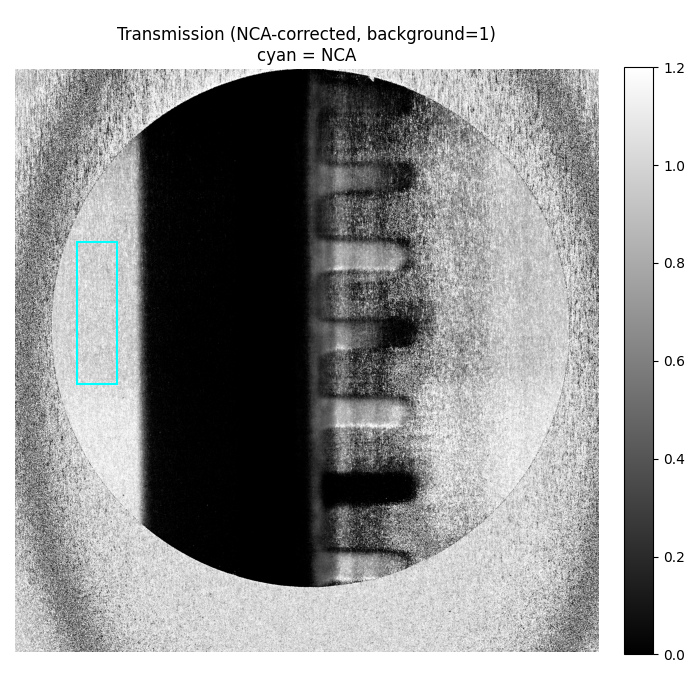

In [57]:
# ============================================================
# STAGE 6b — Transmission: divide by reference, then NCA-correct
#
# transmission = experiment / reference, then divide by the mean of the
# NCA so the open-beam background sits at exactly 1. Each batch is
# corrected independently (so per-batch beam drift is removed) and saved.
# ============================================================
trans_out = output_folder / "transmission"
trans_out.mkdir(parents=True, exist_ok=True)

r0, r1, c0, c1 = nca_roi
ref_safe = np.where(np.abs(ref_corrected) > 1e-6, ref_corrected, np.nan)

trans_batches = []
for b, batch in enumerate(tqdm(exp_batches, desc="Transmission")):
    trans = batch / ref_safe                     # raw transmission
    nca_mean = np.nanmean(trans[r0:r1, c0:c1])   # should be ~1
    trans = trans / nca_mean                     # force NCA background to 1
    trans_batches.append(trans)
    out = trans_out / f"trans_{stem}_batch_{b:04d}.fits"
    fits.writeto(out, trans.astype(np.float32), overwrite=True)

print(f"Saved {len(trans_batches)} transmission images in {trans_out}")
print(f"NCA mean of first batch (pre-correction): "
      f"{np.nanmean((exp_batches[0]/ref_safe)[r0:r1, c0:c1]):.4f}")

# show first transmission image
fig, ax = plt.subplots(figsize=(7, 7))
data = trans_batches[0]
m = bb_mask if bb_mask is not None else np.ones_like(data, bool)
im = ax.imshow(data, cmap="gray", origin="upper", vmin=0, vmax=1.2)
ax.add_patch(plt.Rectangle((c0, r0), c1-c0, r1-r0, edgecolor="cyan",
                            facecolor="none", lw=1.5))
ax.set_title("Transmission (NCA-corrected, background=1)\ncyan = NCA")
ax.axis("off"); fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout(); plt.show()

-ln(T):   0%|          | 0/6 [00:00<?, ?it/s]

Saved 6 optical-thickness images in C:\Users\carreon_r\Documents\90_Python\Binder-collab\2507_BT_ICON_Elec\03_meas\exp3xx\exp300\results\optical_density


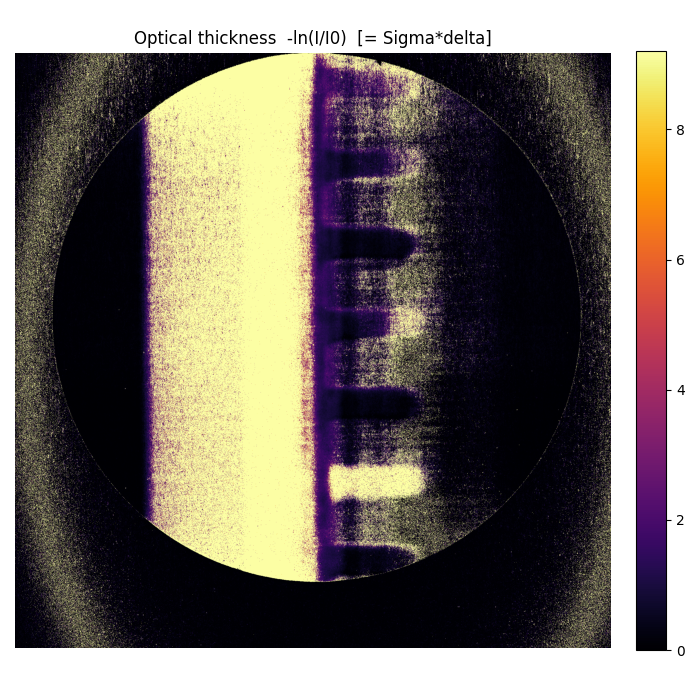

In [58]:
# ============================================================
# STAGE 7 — Optical thickness:  -ln(I/I0)
#
# Beer-Lambert: I/I0 = exp(-Sigma*delta), so -ln(I/I0) = Sigma*delta is
# proportional to the material amount along the beam. This is the
# quantitative image for downstream analysis.
# ============================================================
thick_out = output_folder / "optical_density"
thick_out.mkdir(parents=True, exist_ok=True)

thick_batches = []
for b, trans in enumerate(tqdm(trans_batches, desc="-ln(T)")):
    # clip to a small positive floor so the log is finite where T<=0 (noise/absorbers)
    safe = np.clip(trans, 1e-4, None)
    thick = -np.log(safe)
    thick_batches.append(thick)
    out = thick_out / f"thick_{stem}_batch_{b:04d}.fits"
    fits.writeto(out, thick.astype(np.float32), overwrite=True)

print(f"Saved {len(thick_batches)} optical-thickness images in {thick_out}")

fig, ax = plt.subplots(figsize=(7, 7))
data = thick_batches[0]
m = bb_mask if bb_mask is not None else np.ones_like(data, bool)
vlo, vhi = np.nanpercentile(data[m], [1, 99])
im = ax.imshow(data, cmap="inferno", origin="upper", vmin=max(0, vlo), vmax=vhi)
ax.set_title("Optical thickness  -ln(I/I0)  [= Sigma*delta]")
ax.axis("off"); fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout(); plt.show()

In [60]:
# ============================================================
# STAGE 9 — Provenance: record exactly how this run was produced
# ============================================================
import json
from datetime import datetime

provenance = {
    "timestamp": datetime.now().isoformat(timespec="seconds"),
    "parent_folder": str(parent),
    "folders": {k: str(v) for k, v in folders.items()},
    "reference_used": REFERENCE,
    "batch_size": BATCH_SIZE,
    "projection": PROJECTION,
    "remove_spots": bool(REMOVE_SPOTS),
    "n_exp_frames": len(exp_imgs),
    "n_output_batches": len(trans_batches),
    "nca_roi_row0_row1_col0_col1": list(nca_roi),
    "sbkg": None if sbkg is None else {
        "n_dots_used": int(len(bb_centres)),
        "pct_of_ob_p5_p95": [
            float(np.percentile((100*sbkg/np.maximum(refs.get('ob', ref_corrected),1e-6))[bb_mask], 5)),
            float(np.percentile((100*sbkg/np.maximum(refs.get('ob', ref_corrected),1e-6))[bb_mask], 95)),
        ],
    },
    "outputs": {
        "exp_corrected": str(output_folder / "exp_corrected"),
        "transmission": str(output_folder / "transmission"),
        "optical_density": str(output_folder / "optical_density"),
    },
}

prov_path = output_folder / f"provenance_{stem}.json"
prov_path.write_text(json.dumps(provenance, indent=2))
print(f"Provenance saved to {prov_path}")
print(json.dumps(provenance, indent=2))

Provenance saved to C:\Users\carreon_r\Documents\90_Python\Binder-collab\2507_BT_ICON_Elec\03_meas\exp3xx\exp300\results\provenance_meas.json
{
  "timestamp": "2026-06-22T17:18:43",
  "parent_folder": "C:\\Users\\carreon_r\\Documents\\90_Python\\Binder-collab\\2507_BT_ICON_Elec\\03_meas\\exp3xx\\exp300",
  "folders": {
    "bb": "C:\\Users\\carreon_r\\Documents\\90_Python\\Binder-collab\\2507_BT_ICON_Elec\\03_meas\\exp3xx\\exp300\\refs\\bb",
    "dc": "C:\\Users\\carreon_r\\Documents\\90_Python\\Binder-collab\\2507_BT_ICON_Elec\\03_meas\\exp3xx\\exp300\\refs\\dc",
    "ob": "C:\\Users\\carreon_r\\Documents\\90_Python\\Binder-collab\\2507_BT_ICON_Elec\\03_meas\\exp3xx\\exp300\\refs\\ob",
    "dry": "C:\\Users\\carreon_r\\Documents\\90_Python\\Binder-collab\\2507_BT_ICON_Elec\\03_meas\\exp3xx\\exp300\\dry",
    "exp": "C:\\Users\\carreon_r\\Documents\\90_Python\\Binder-collab\\2507_BT_ICON_Elec\\03_meas\\exp3xx\\exp300\\meas"
  },
  "reference_used": "dry",
  "batch_size": 10,
  "project